# Lab 03 — Exercise 1 — Sentiment Analysis

**Môn học:** Deep Learning — UTH. **Bài toán:** phân tích cảm xúc và phân loại văn bản nhị phân với Hugging Face.

Notebook có hai chế độ. **`MODE="view"`** đọc kết quả Kaggle đã xác minh và tạo hoặc dùng lại run phân tích chứa hình/bảng; không tải dataset/model và không train. **`MODE="train"`** gọi cùng module với CLI để thực thi thí nghiệm mới. Output đã lưu trong notebook là một lượt chạy `view`, không phải một lần GPU training mới.

Mỗi trực quan hóa hiển thị bên dưới được đọc từ file ảnh trong `outputs/`; bảng có bản JSON nguồn tương ứng. Artifacts thí nghiệm cũ không bị ghi đè. Các bảng JSON phục vụ tái tính toán và kiểm tra, còn hình phục vụ diễn giải bài. Cài môi trường theo [README](../README.md) trước khi chạy và xem [description](../description_lab_03.md) cho các quyết định phạm vi.

**Cách đọc số liệu:** các số trong phần giải thích là kết quả Kaggle tham chiếu có run ID cụ thể. Khi `MODE="train"`, bảng và hình được tính từ run mới; không gán số tham chiếu cho kết quả vừa chạy.

## Roadmap — Exercise 1

| Phase | Câu hỏi cần trả lời | Module / file tham chiếu | Đầu vào | Artifact / bằng chứng đầu ra |
|---|---|---|---|---|
| P01 — Setup | Đang xem bằng chứng hay chạy inference mới? | [workflow.py](../src/workflow.py), [config.json](../config/config.json) | Config và registry | Run ID, config, snapshot môi trường |
| P02 — Pretrained model | Model nào đã biết sentiment? | [classifier.py](../src/models/classifier.py): `load_model` | DistilBERT fine-tuned SST-2 | Model/tokenizer dùng chung cho hai cách suy luận |
| P03 — Tokenization | Câu được mã hóa như thế nào? | [workflow.py](../src/workflow.py): `exercise1` | Câu văn bản mẫu | `tokenizer_breakdown.json`, `tokenizer_table.png` |
| P04 — Forward | Logits khác xác suất ở đâu? | [classifier.py](../src/models/classifier.py): `manual_predict` | `input_ids`, `attention_mask` | `predictions.json`, `sentiment_predictions.png` |
| P05 — Đối chiếu API | Pipeline có khớp manual không? | [classifier.py](../src/models/classifier.py): `compare_inference` | Cùng model, tokenizer, câu mẫu | `pipeline_manual_comparison.png`, `summary.json` |
| P06 — Audit & bàn giao | Output có còn nguyên và tái đọc được? | [evidence.py](../src/evidence.py), [analysis.py](../src/analysis.py), [runs.py](../src/utils/runs.py) | Predictions và manifest | Audit, SHA256, run phân tích riêng trong `outputs/runs/` |

Sơ đồ luồng: **text → tokenizer → model forward → logits → softmax → argmax → label/score**. Exercise 1 không dùng optimizer và không cập nhật trọng số.

In [1]:
from pathlib import Path
import sys
import json

LAB = next((p / "labs/lab03" if (p / "labs/lab03/src/workflow.py").is_file() else p
            for p in [Path.cwd(), *Path.cwd().parents]
            if (p / "labs/lab03/src/workflow.py").is_file() or (p / "src/workflow.py").is_file()), None)
if LAB is None:
    raise RuntimeError("Open this notebook inside the Lab-DL repository")
sys.path.insert(0, str(LAB.parents[1]))

import pandas as pd
from IPython.display import display, Image, Markdown
from labs.lab03.src.workflow import read_config, exercise1, finetune
from labs.lab03.src.evidence import selected_run, audit_exercise1, audit_finetuning, read_json
from labs.lab03.src.analysis import ensure_analysis, ensure_exercise1_analysis

# view: xem kết quả có sẵn; chỉ tạo/cache artifacts phân tích, không tải model hay train.
# train: tạo thí nghiệm mới; fine-tuning mặc định cần GPU CUDA.
MODE = "view"
assert MODE in {"view", "train"}
config = read_config()

def show_figure(path, caption):
    path = Path(path)
    if not path.is_file():
        raise FileNotFoundError(f"Missing saved visualization: {path}")
    display(Markdown(f"**{caption}**"))
    display(Image(filename=str(path)))

print("Chế độ:", MODE)
print("Nguồn bài:", LAB)
print("Hình và bảng được đọc từ artifacts đã lưu trong outputs/.")
from labs.lab03.src.threshold_analysis import ensure_threshold_analysis

Chế độ: view
Nguồn bài: /workspace/Lab-DL/labs/lab03
Hình và bảng được đọc từ artifacts đã lưu trong outputs/.


## 1.1. Mô hình được sử dụng và lý do lựa chọn

`distilbert/distilbert-base-uncased-finetuned-sst-2-english` đã được fine-tune cho sentiment nhị phân trên SST-2. Model này phù hợp để thực hành inference ngay, khác backbone nền ở Exercise 2. Tên lớp 0/1 được model ánh xạ sang `NEGATIVE`/`POSITIVE`.

`pipeline("sentiment-analysis")` là API cấp cao; nó không phải một thuật toán khác với forward thủ công. Hai cách phải dùng cùng checkpoint, cùng tokenizer và cùng thiết lập truncation để đối chiếu có ý nghĩa. Ba câu mẫu kiểm tra API chỉ là ví dụ minh họa, không phải test set để báo cáo accuracy tổng quát.

In [2]:
exercise1_run = exercise1(config) if MODE == "train" else selected_run("exercise1")
exercise1_audit = audit_exercise1(exercise1_run)
exercise1_analysis = ensure_exercise1_analysis(exercise1_run)
ex1_summary = read_json(exercise1_analysis / "summary.json")
print("Run inference:", exercise1_run.name)
print("Run phân tích đã lưu:", exercise1_analysis)
print("Tệp gốc khớp SHA256:", exercise1_audit["verified_files"])

Run inference: 20261025T181532Z_exercise1_71da6f40
Run phân tích đã lưu: /workspace/Lab-DL/labs/lab03/outputs/runs/20261026T125627Z_exercise1_analysis_6a474f62
Tệp gốc khớp SHA256: 6


## 1.2. Tokenization — từ văn bản sang tensor

WordPiece có thể biểu diễn một từ bằng nhiều subword; token không nhất thiết trùng một từ. Tokenizer thêm `[CLS]` ở đầu và `[SEP]` ở cuối. `input_ids` là các ID vocabulary, không phải giá trị sentiment. `attention_mask` bằng 1 tại token thực và bằng 0 tại padding.

Trong câu đơn không có padding, mask toàn 1 là đúng. Với batch nhiều câu, padding tạo tensor chữ nhật `(B,S)` và mask giúp attention bỏ qua phần đệm. Tokenizer còn áp dụng quy tắc của model uncased; không tự đổi vocabulary hoặc tải tokenizer của checkpoint khác.

Hình dưới là bảng token có vị trí, ID và mask; các giá trị nguồn nằm trong `tokenizer_breakdown.json` và `summary.json` của run phân tích.

**Tokenization breakdown của câu mẫu**

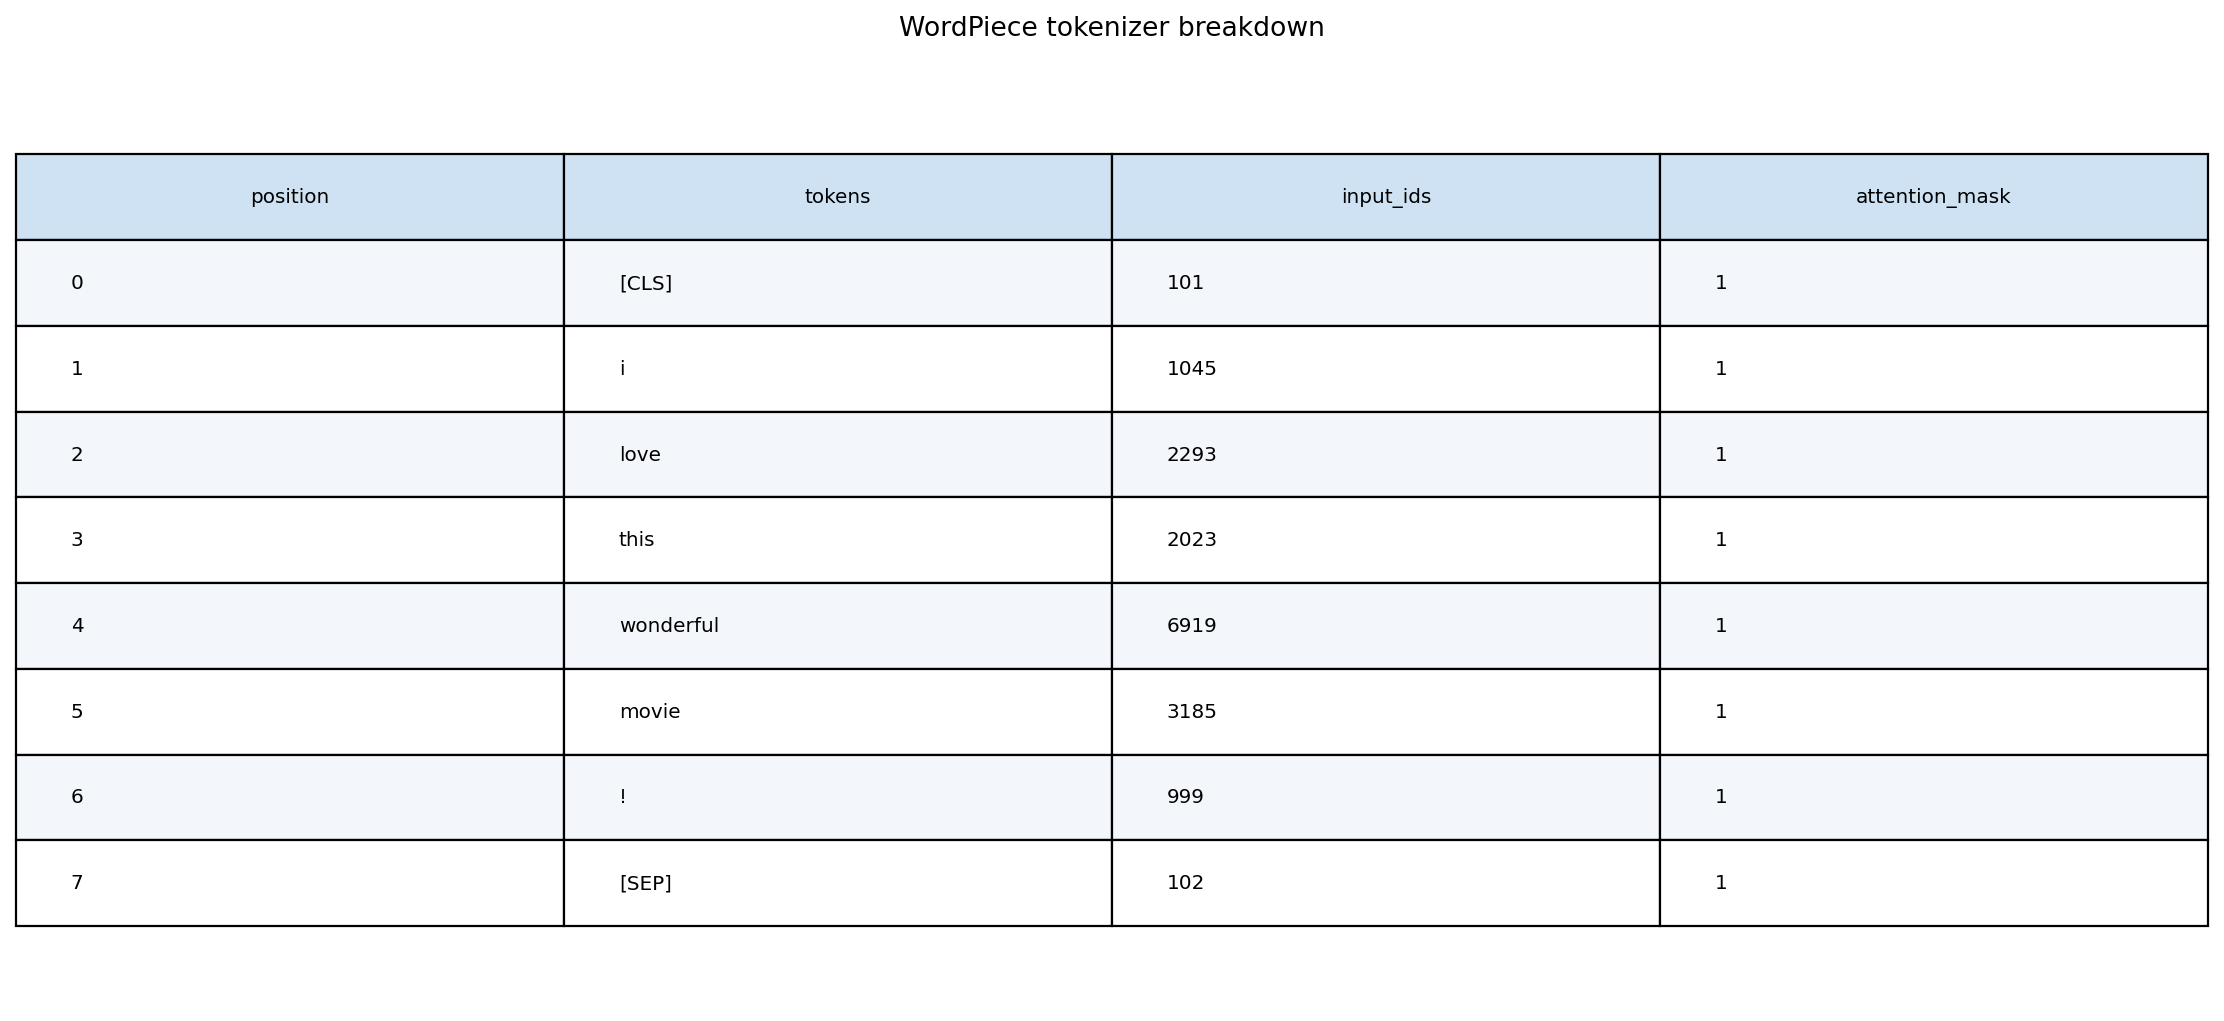

,position,tokens,input_ids,attention_mask
0,0,[CLS],101,1
1,1,i,1045,1
2,2,love,2293,1
3,3,this,2023,1
4,4,wonderful,6919,1
5,5,movie,3185,1
6,6,!,999,1
7,7,[SEP],102,1


In [3]:
show_figure(exercise1_analysis / "tokenizer_table.png", "Tokenization breakdown của câu mẫu")
display(pd.DataFrame(ex1_summary["tokenization"]))

## 1.3. Forward pass, logits và softmax

Model trả hai logits $z_0,z_1$. Đây là điểm số chưa chuẩn hóa, có thể âm hoặc lớn hơn 1. Softmax chuyển chúng thành xác suất:

$$p_c=\frac{\exp(z_c)}{\exp(z_0)+\exp(z_1)},\qquad \widehat y=\arg\max_c p_c.$$

Mẫu code tương đương luồng thực trong `manual_predict`:

```python
model.eval()
encoded = tokenizer(texts, padding=True, truncation=True,
                    max_length=128, return_tensors="pt")
with torch.inference_mode():
    logits = model(**encoded).logits
    probabilities = logits.softmax(dim=-1)
```

`eval()` tắt hành vi training của dropout; `inference_mode()` không ghi đồ thị gradient. Hai lời gọi có vai trò khác nhau và thường được dùng cùng nhau khi suy luận.

**Xác suất và nhãn sentiment trên ba câu mẫu**

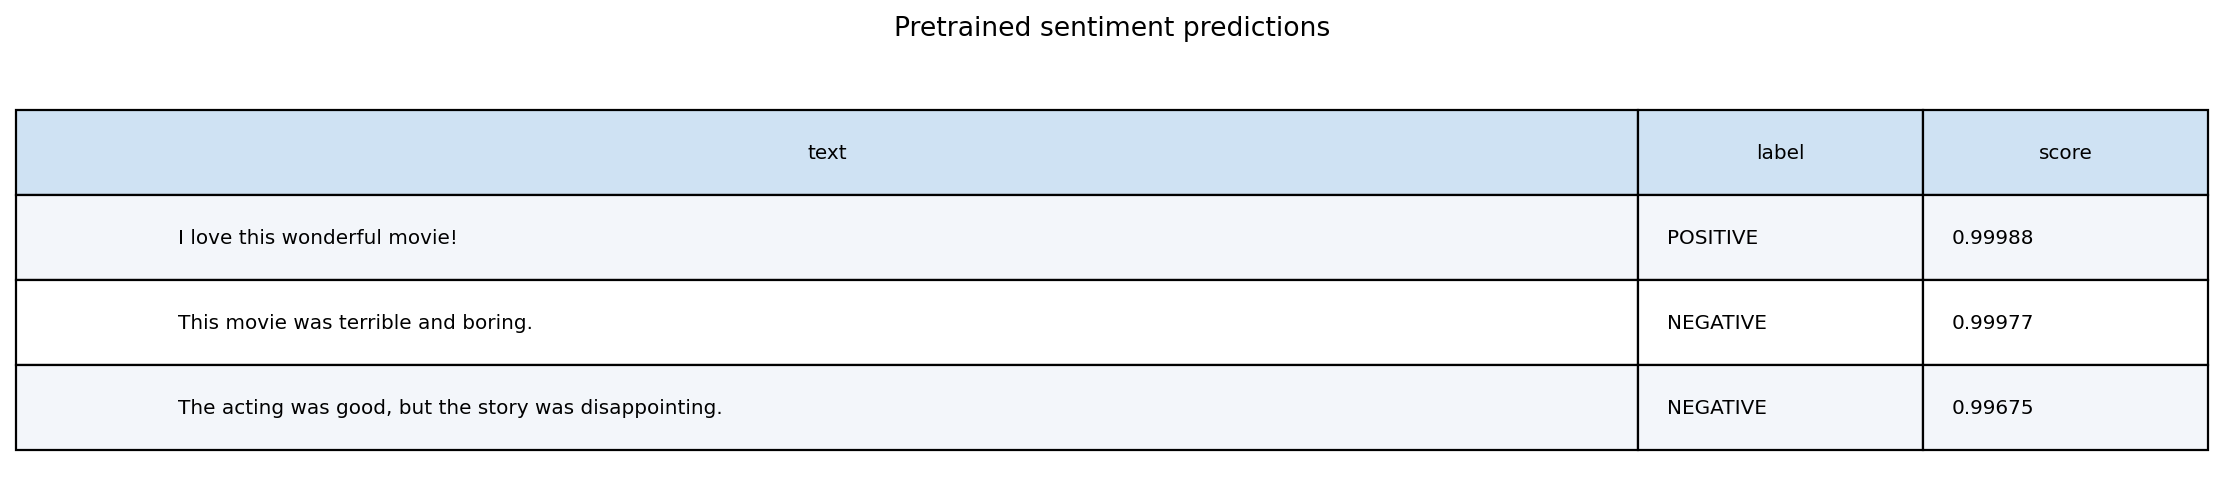

,text,label,score
0,I love this wonderful movie!,POSITIVE,0.999878
1,This movie was terrible and boring.,NEGATIVE,0.999768
2,"The acting was good, but the story was disappo...",NEGATIVE,0.996749


In [4]:
show_figure(exercise1_analysis / "sentiment_predictions.png", "Xác suất và nhãn sentiment trên ba câu mẫu")
display(pd.DataFrame(ex1_summary["predictions"])[["text", "label", "score"]])

## 1.4. Pipeline và manual inference có thật sự nhất quán?

Code kiểm tra nhãn giống nhau và độ lệch score không quá `1e-5`. Tolerance nhỏ chấp nhận sai số số học của cùng pipeline; không được thay model hoặc bỏ assertion để test qua. Khi kiểm tra này thất bại, cần kiểm tra checkpoint, tokenizer, device, precision và trạng thái eval trước khi diễn giải như một khác biệt thuật toán.

Đối chiếu dùng cùng bộ ba câu: câu khen trực tiếp, câu chê trực tiếp và câu có cấu trúc “good, but … disappointing”. Câu cuối minh họa rằng sentiment phụ thuộc toàn câu, không chỉ việc xuất hiện một tính từ tích cực.

**Đối chiếu pipeline/manual được lưu thành ảnh**

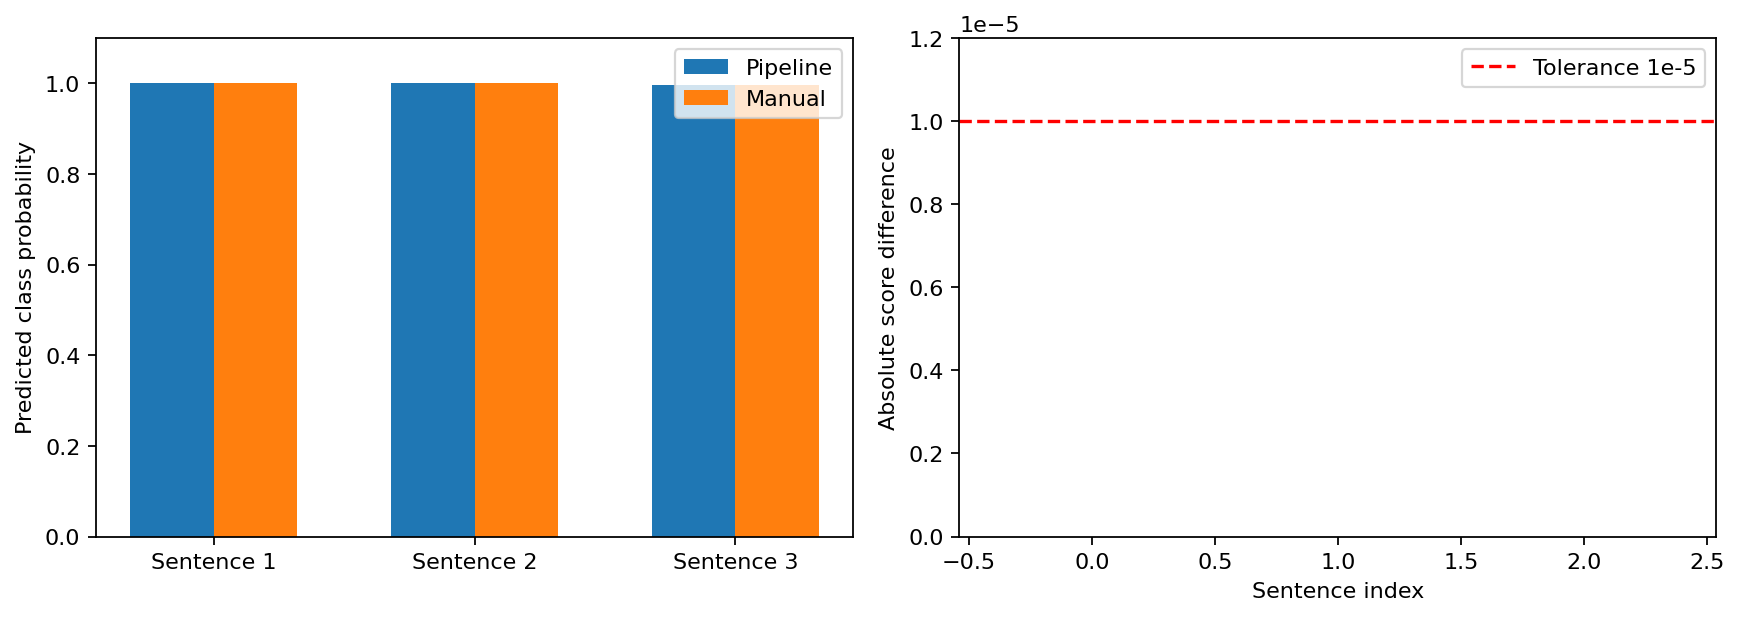

,text,pipeline_label,manual_label,pipeline_score,manual_score,difference
0,I love this wonderful movie!,POSITIVE,POSITIVE,0.999878,0.999878,0.0
1,This movie was terrible and boring.,NEGATIVE,NEGATIVE,0.999768,0.999768,0.0
2,"The acting was good, but the story was disappo...",NEGATIVE,NEGATIVE,0.996749,0.996749,0.0


In [5]:
show_figure(exercise1_analysis / "pipeline_manual_comparison.png", "Đối chiếu pipeline/manual được lưu thành ảnh")
display(pd.DataFrame(ex1_summary["comparison"]))

## 1.5. Diễn giải và giới hạn của confidence

Câu “I love this wonderful movie!” được mô hình gán Positive; “terrible and boring” được gán Negative. Ở câu có nhượng bộ, model chọn Negative. Confidence là xác suất theo model, không phải bằng chứng câu chắc chắn đúng với xác suất đó ngoài thực tế.

Các ví dụ trên chứng minh quy trình inference và đối chiếu API hoạt động. Chúng không chứng minh model đã được đánh giá tổng quát trên tiếng Việt, mỉa mai, lĩnh vực khác hoặc câu dài. Dataset/training của Exercise 1 là SST-2 của model pretrained, không phải một lần fine-tuning Rotten Tomatoes mới trong notebook này.

## 1.6. Artifact handoff của Exercise 1

| Artifact | Vai trò |
|---|---|
| Run gốc: `tokenizer_breakdown.json` | Token/ID/mask thực của câu mẫu |
| Run gốc: `predictions.json` | Nhãn, score và xác suất của hai phương pháp |
| Run phân tích: `summary.json` | Bảng đã chuẩn hóa để tái hiển thị |
| Run phân tích: ba PNG | Trực quan hóa được hiển thị trong notebook |
| `config.json`, snapshot, `console.log`, `manifest.json` | Truy vết điều kiện chạy và bytes của artifacts |

Hình được đọc từ file đã lưu, không chỉ tồn tại tạm trong notebook. Run phân tích giữ tham chiếu tới run inference và không ghi đè dữ liệu Kaggle gốc.